# Análisis exploratorio · Métricas sociales, económicas y digitales de Latinoamérica

**Dataset:** 15 países × 10 trimestres (2023-T1 → 2025-T2) = 150 filas, 22 columnas (datos simulados).

**Contenido**
1. Carga, derivación de variables y validación de calidad
2. Estadística descriptiva
3. Distribuciones (histogramas)
4. Comparaciones categóricas (barras)
5. Relaciones entre variables (scatterplots y correlaciones)
6. Hallazgos clave


## 1. Carga y preparación

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (10, 5.5)})
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 50

DATA_PATH = Path("dataset_latam.csv")
df = pd.read_csv(DATA_PATH, parse_dates=["fecha"])
print(f"Filas: {len(df)} | Columnas: {df.shape[1]}")
df.head()

Filas: 150 | Columnas: 22


,id,fecha,pais,subregion,nivel_ingreso,red_social_dominante,sector_vc_lider,poblacion_millones,pib_per_capita_usd,tasa_desempleo_pct,inflacion_anual_pct,pobreza_pct,penetracion_internet_pct,usuarios_redes_millones,horas_diarias_redes,pagos_digitales_pct,ventas_ecommerce_musd,startups_fintech,velocidad_internet_mbps,inversion_vc_musd,pago_instantaneo,ley_datos_personales
0,1,2023-03-31,Brasil,Sudamérica,Medio-alto,WhatsApp,Fintech,216.40,10100,8.80,5.80,31.60,81.00,158.00,3.60,52,10800,1230,95,520,True,True
1,2,2023-06-30,Brasil,Sudamérica,Medio-alto,WhatsApp,Fintech,216.50,10180,8.00,3.90,31.20,81.60,159.00,3.60,54,11300,1245,98,480,True,True
2,3,2023-09-30,Brasil,Sudamérica,Medio-alto,WhatsApp,E-commerce,216.60,10270,7.80,5.20,30.80,82.20,160.00,3.70,56,12100,1262,101,610,True,True
3,4,2023-12-31,Brasil,Sudamérica,Medio-alto,WhatsApp,Fintech,216.70,10360,7.40,4.60,30.30,82.80,161.00,3.70,58,15200,1280,104,700,True,True
4,5,2024-03-31,Brasil,Sudamérica,Medio-alto,WhatsApp,Logística,216.90,10450,7.90,4.50,29.90,83.40,163.00,3.70,60,12000,1295,108,450,True,True


In [21]:
# --- Grupos de columnas ---
NUM_BASE = [
    "poblacion_millones", "pib_per_capita_usd", "tasa_desempleo_pct", "inflacion_anual_pct",
    "pobreza_pct", "penetracion_internet_pct", "usuarios_redes_millones", "horas_diarias_redes",
    "pagos_digitales_pct", "ventas_ecommerce_musd", "startups_fintech",
    "velocidad_internet_mbps", "inversion_vc_musd",
]
COL_CAT = ["pais", "subregion", "nivel_ingreso", "red_social_dominante", "sector_vc_lider"]
COL_BOOL = ["pago_instantaneo", "ley_datos_personales"]
ORDEN_INGRESO = ["Medio-bajo", "Medio-alto", "Alto"]

# --- Variables derivadas (útiles para comparar países de distinto tamaño) ---
df["anio"] = df["fecha"].dt.year
df["trimestre"] = df["fecha"].dt.quarter
df["periodo"] = df["anio"].astype(str) + "-T" + df["trimestre"].astype(str)
df["usuarios_pct_pob"] = df["usuarios_redes_millones"] / df["poblacion_millones"] * 100
df["ecommerce_per_capita_usd"] = df["ventas_ecommerce_musd"] / df["poblacion_millones"]   # MUSD / M hab = USD por persona
df["fintech_por_millon_hab"] = df["startups_fintech"] / df["poblacion_millones"]
df["vc_per_capita_usd"] = df["inversion_vc_musd"] / df["poblacion_millones"]
DERIVADAS = ["usuarios_pct_pob", "ecommerce_per_capita_usd", "fintech_por_millon_hab", "vc_per_capita_usd"]

df["nivel_ingreso"] = pd.Categorical(df["nivel_ingreso"], categories=ORDEN_INGRESO, ordered=True)
for c in COL_BOOL:
    df[c] = df[c].astype(bool)

# Fotografía del último trimestre
ULTIMO = df["fecha"].max()
PRIMERO = df["fecha"].min()
ult = df[df["fecha"] == ULTIMO].copy()
ult_i = ult.set_index("pais")
print(f"Periodo: {PRIMERO.date()} → {ULTIMO.date()}")

Periodo: 2023-03-31 → 2025-06-30


## 2. Estadística descriptiva

In [24]:
df[NUM_BASE + DERIVADAS].describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]

,count,mean,std,min,25%,50%,75%,max
poblacion_millones,150.00,40.61,56.53,3.50,7.00,18.40,46.27,217.40
pib_per_capita_usd,150.00,"10,695.60","5,583.46","3,500.00","6,472.50","10,495.00","14,540.00","22,800.00"
tasa_desempleo_pct,150.00,6.08,2.27,2.40,3.82,5.95,7.80,12.00
inflacion_anual_pct,150.00,26.35,71.70,-1.40,2.23,4.40,6.45,440.00
pobreza_pct,150.00,30.10,14.67,8.50,20.15,27.40,36.40,66.00
penetracion_internet_pct,150.00,78.85,9.63,55.00,72.60,80.70,85.72,94.00
usuarios_redes_millones,150.00,29.41,42.66,2.80,5.00,12.00,35.00,168.00
horas_diarias_redes,150.00,3.50,0.23,3.00,3.30,3.50,3.70,4.00
pagos_digitales_pct,150.00,42.20,13.59,15.00,32.00,40.50,52.00,72.00
ventas_ecommerce_musd,150.00,"2,080.73","3,474.12",120.00,240.00,405.00,"2,400.00","17,000.00"


In [25]:
for c in COL_CAT:
    print(f"\n── {c} ──")
    print(df[c].value_counts().to_string())
print("\n── Booleanas (% de filas en True) ──")
print((df[COL_BOOL].mean() * 100).round(1).to_string())


── pais ──
pais
Brasil                  10
México                  10
Argentina               10
Colombia                10
Chile                   10
Perú                    10
Ecuador                 10
Uruguay                 10
Costa Rica              10
Panamá                  10
Paraguay                10
Bolivia                 10
Guatemala               10
República Dominicana    10
Venezuela               10

── subregion ──
subregion
Sudamérica       100
Centroamérica     30
Norteamérica      10
Caribe            10

── nivel_ingreso ──
nivel_ingreso
Medio-alto    100
Alto           30
Medio-bajo     20

── red_social_dominante ──
red_social_dominante
WhatsApp     60
Instagram    50
Facebook     30
TikTok       10

── sector_vc_lider ──
sector_vc_lider
Fintech          99
E-commerce       16
Logística         9
Agritech          9
Edtech            9
Salud digital     8

── Booleanas (% de filas en True) ──
pago_instantaneo       37.30
ley_datos_personales   68.00


## 3. Distribuciones (histogramas)

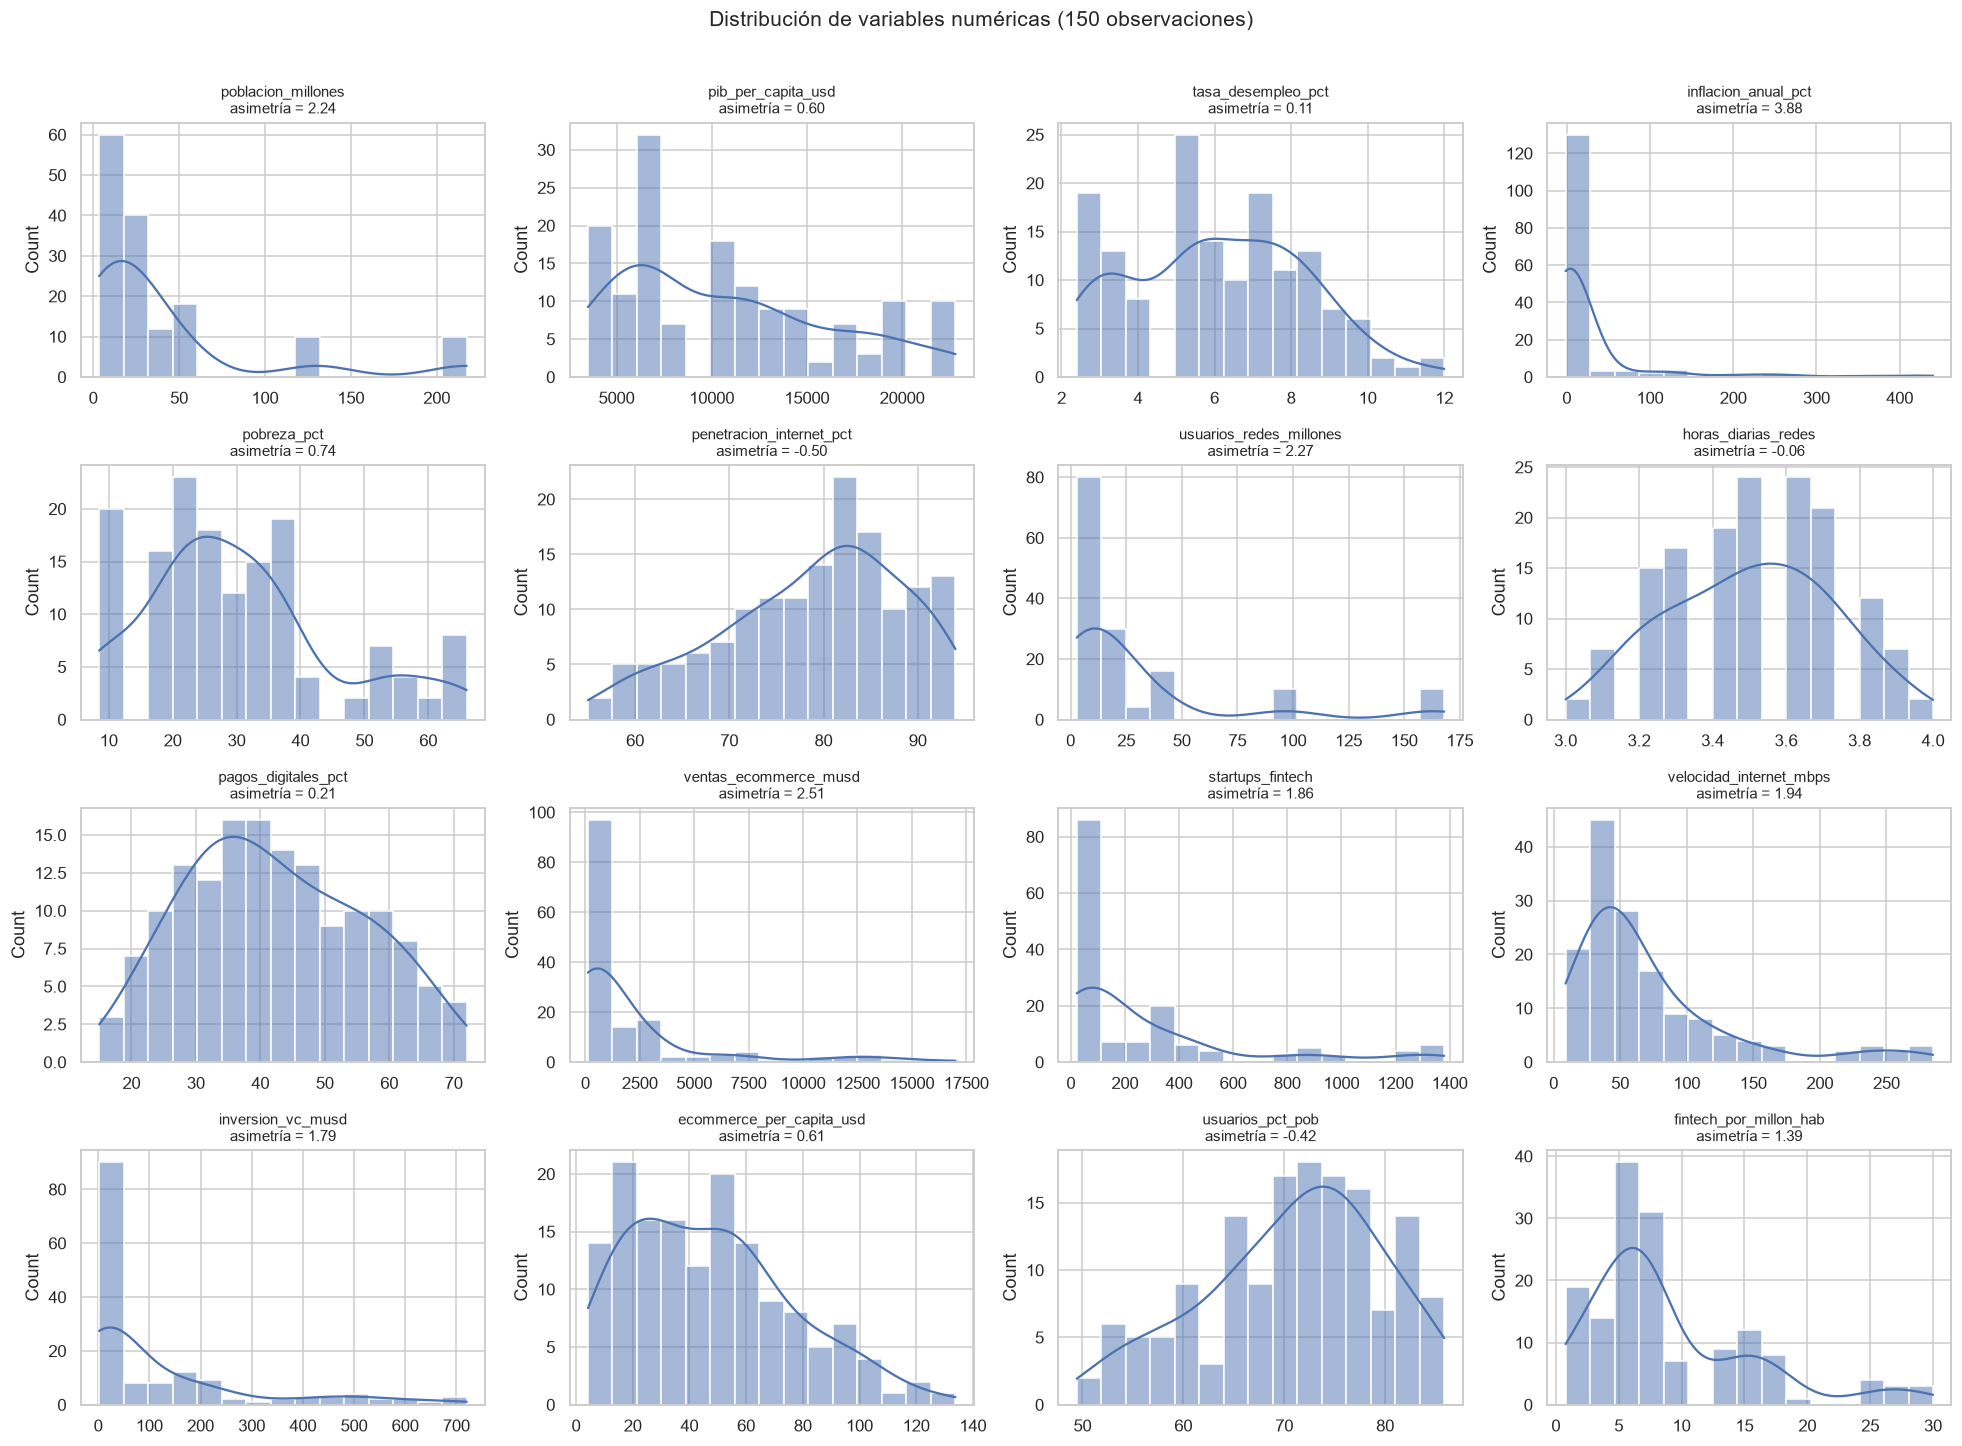

In [26]:
cols = NUM_BASE + ["ecommerce_per_capita_usd", "usuarios_pct_pob", "fintech_por_millon_hab"]
fig, axes = plt.subplots(4, 4, figsize=(18, 13))
for ax, c in zip(axes.ravel(), cols):
    sns.histplot(df[c], bins=15, kde=True, ax=ax, color="#4C72B0")
    ax.set_title(f"{c}\nasimetría = {df[c].skew():.2f}", fontsize=10)
    ax.set_xlabel("")
for ax in axes.ravel()[len(cols):]:
    ax.set_visible(False)
plt.suptitle("Distribución de variables numéricas (150 observaciones)", y=1.01, fontsize=14)
plt.tight_layout(); plt.show()

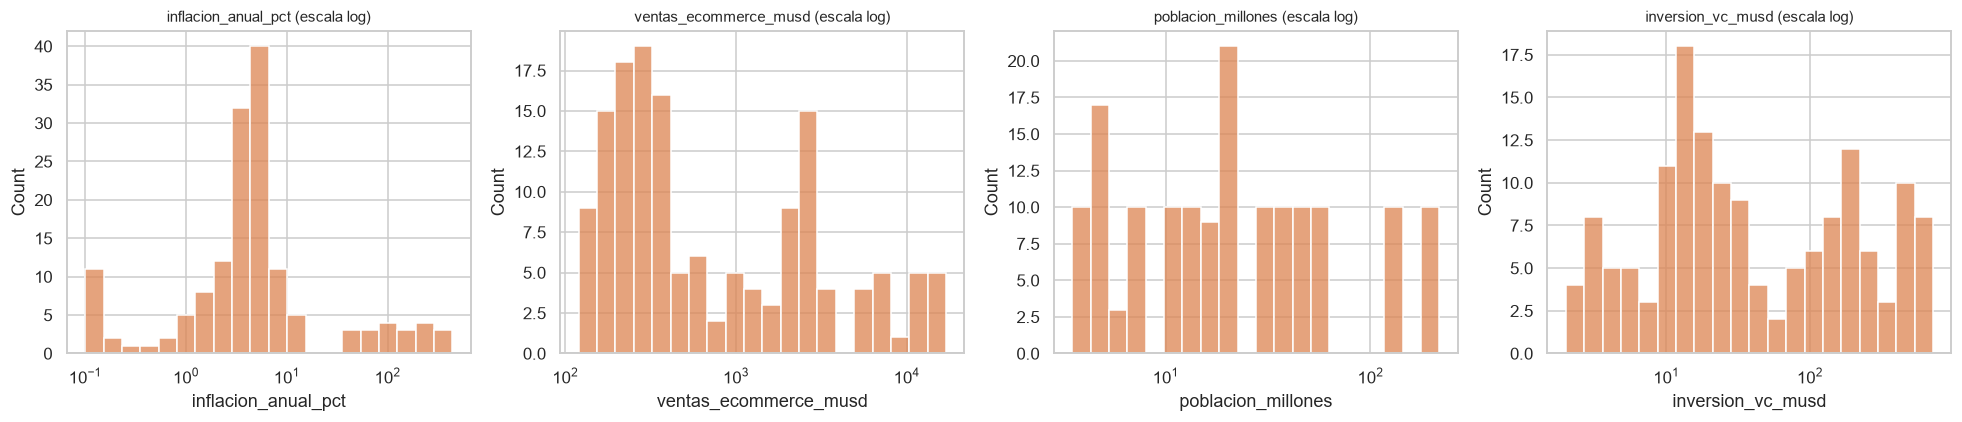

In [27]:
# Variables muy asimétricas: se ven mejor en escala logarítmica
sesgadas = ["inflacion_anual_pct", "ventas_ecommerce_musd", "poblacion_millones", "inversion_vc_musd"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, sesgadas):
    x = df[c].clip(lower=0.1)  # evita log de negativos/cero (p. ej. inflación < 0)
    sns.histplot(x, bins=20, log_scale=True, ax=ax, color="#DD8452")
    ax.set_title(f"{c} (escala log)", fontsize=10)
plt.tight_layout(); plt.show()

## 4. Comparaciones categóricas (barras)

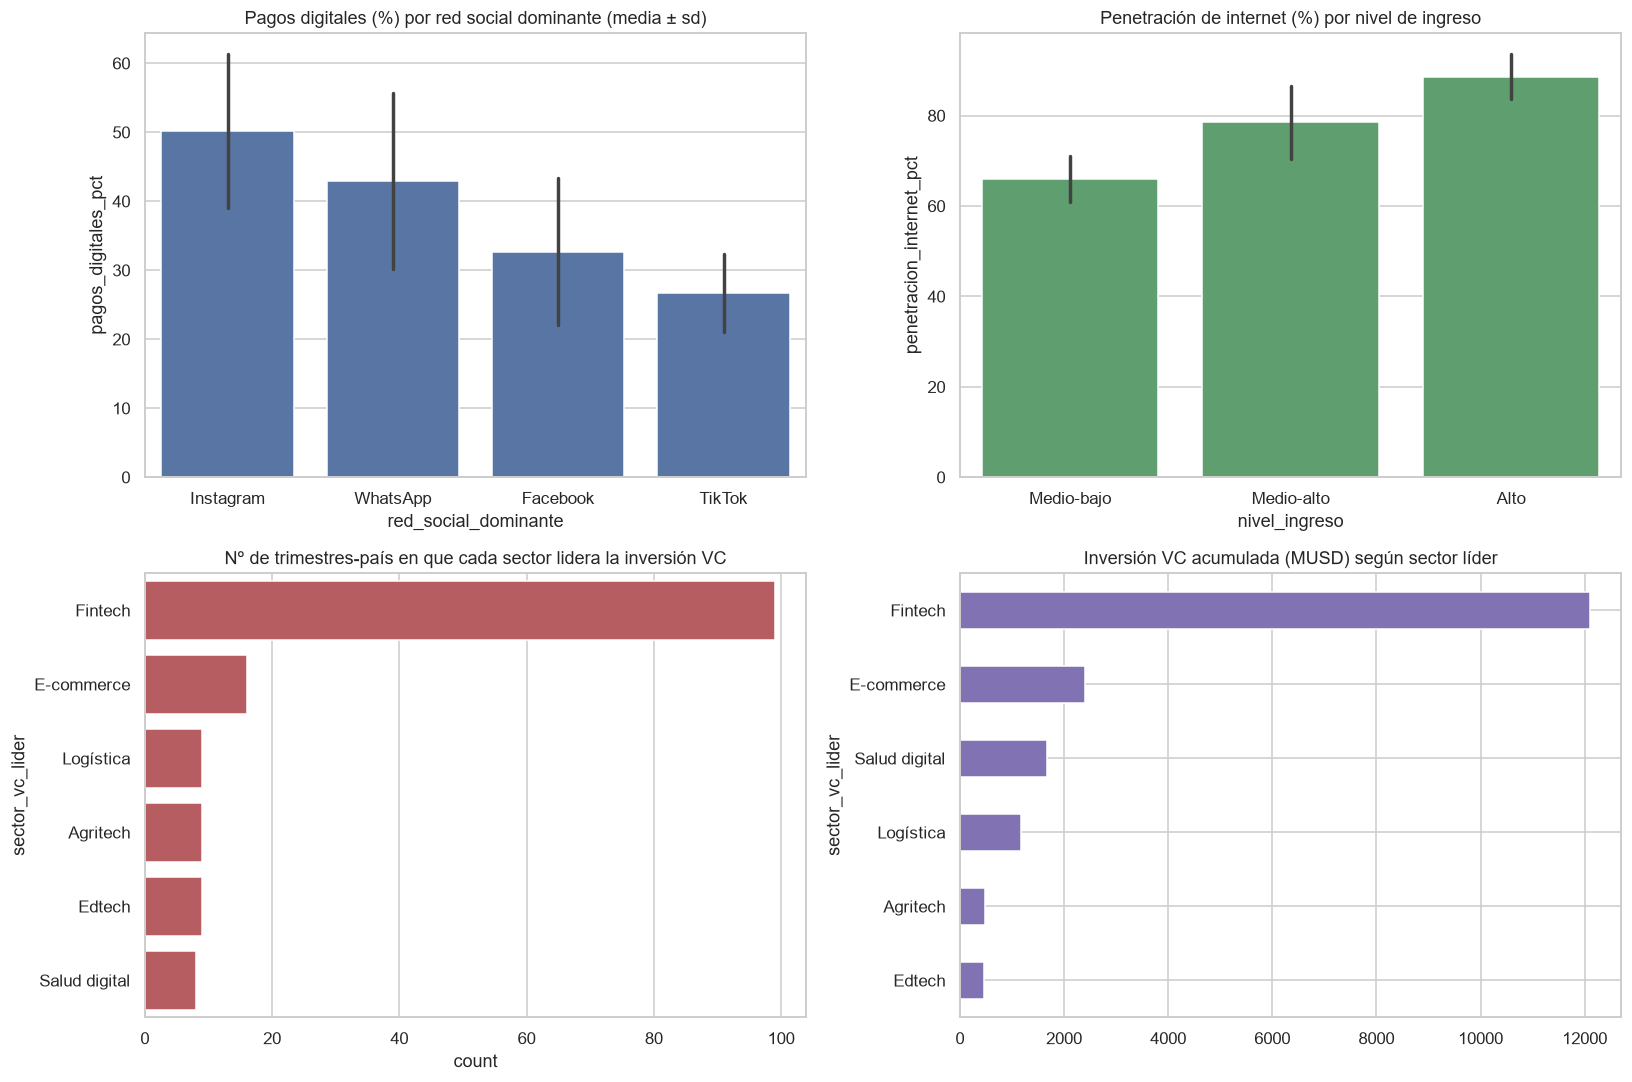

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

orden_rs = df.groupby("red_social_dominante")["pagos_digitales_pct"].mean().sort_values(ascending=False).index
sns.barplot(data=df, x="red_social_dominante", y="pagos_digitales_pct", order=orden_rs,
            errorbar="sd", color="#4C72B0", ax=axes[0, 0])
axes[0, 0].set_title("Pagos digitales (%) por red social dominante (media ± sd)")

sns.barplot(data=df, x="nivel_ingreso", y="penetracion_internet_pct", order=ORDEN_INGRESO,
            errorbar="sd", color="#55A868", ax=axes[0, 1])
axes[0, 1].set_title("Penetración de internet (%) por nivel de ingreso")

sns.countplot(data=df, y="sector_vc_lider", order=df["sector_vc_lider"].value_counts().index,
              color="#C44E52", ax=axes[1, 0])
axes[1, 0].set_title("Nº de trimestres-país en que cada sector lidera la inversión VC")

vc_sector = df.groupby("sector_vc_lider")["inversion_vc_musd"].sum().sort_values()
vc_sector.plot.barh(color="#8172B3", ax=axes[1, 1])
axes[1, 1].set_title("Inversión VC acumulada (MUSD) según sector líder")
plt.tight_layout(); plt.show()

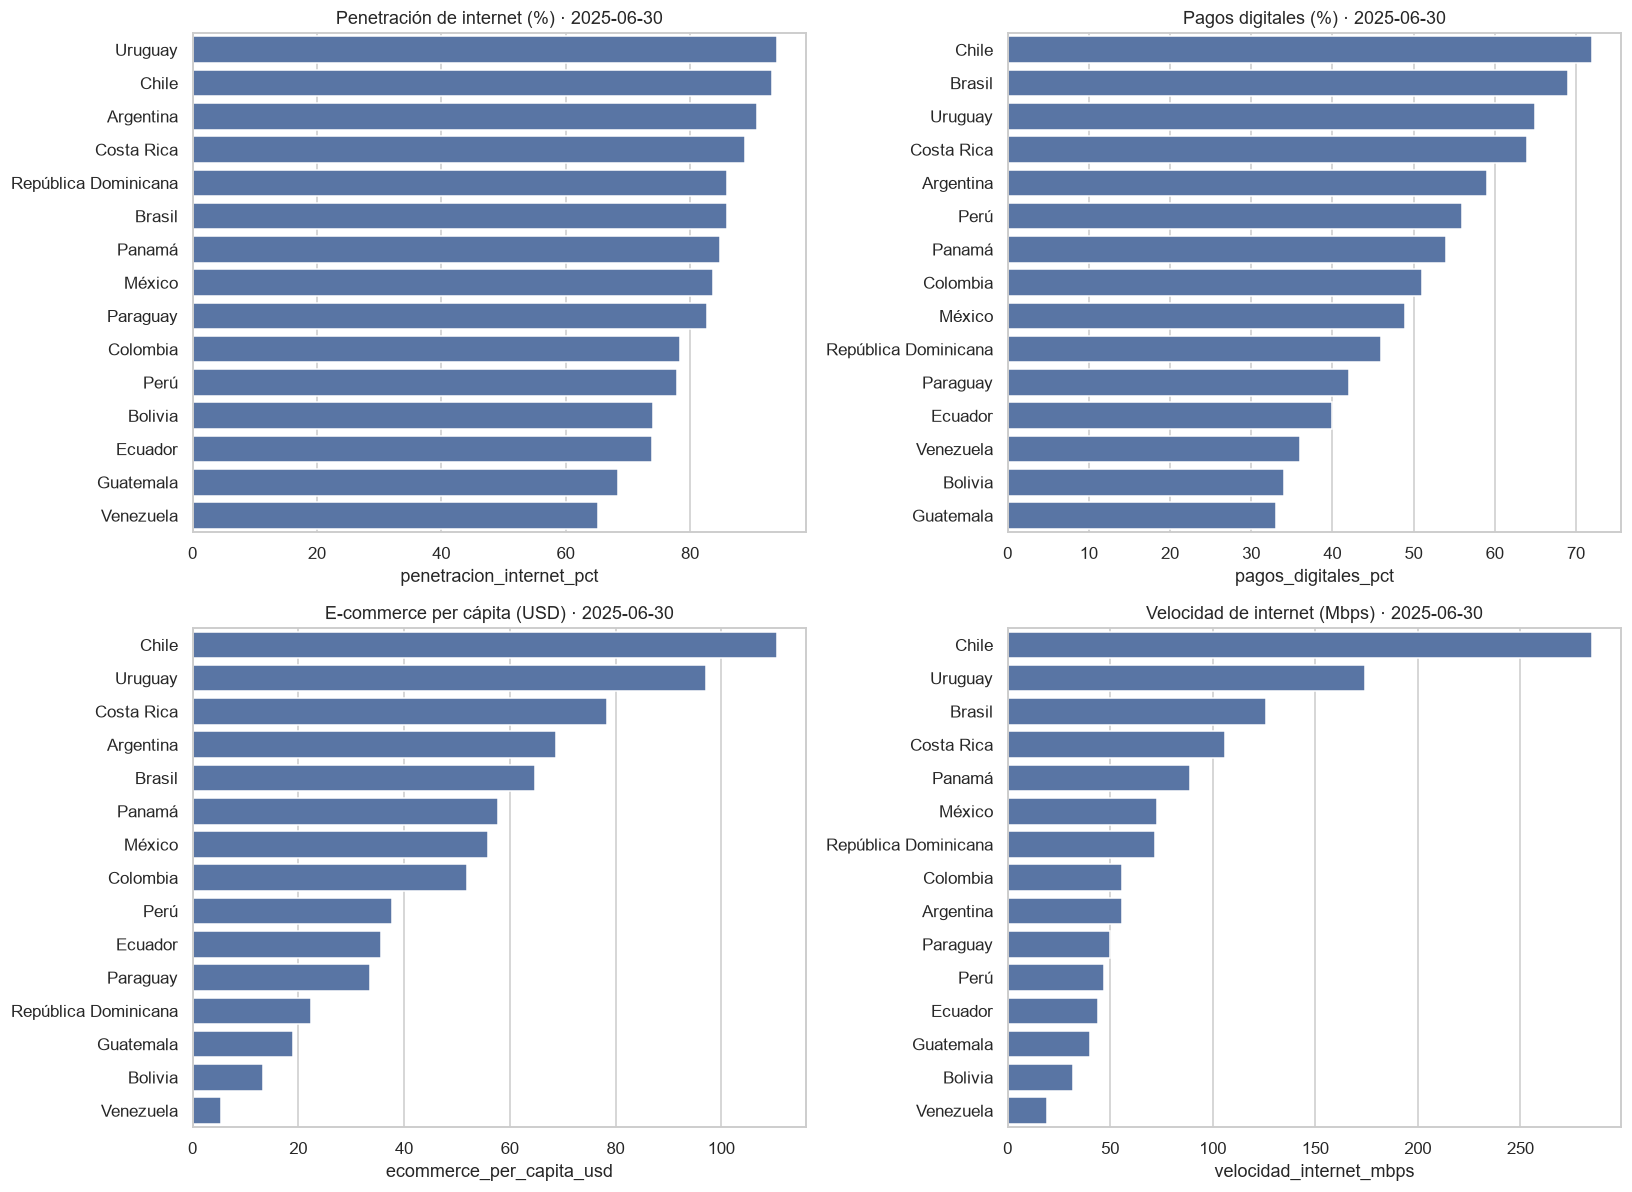

In [29]:
# Ranking de países en el último trimestre (4 KPIs del dashboard)
kpis_bar = [
    ("penetracion_internet_pct", "Penetración de internet (%)"),
    ("pagos_digitales_pct", "Pagos digitales (%)"),
    ("ecommerce_per_capita_usd", "E-commerce per cápita (USD)"),
    ("velocidad_internet_mbps", "Velocidad de internet (Mbps)"),
]
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
for ax, (c, t) in zip(axes.ravel(), kpis_bar):
    d = ult.sort_values(c, ascending=False)
    sns.barplot(data=d, y="pais", x=c, color="#4C72B0", ax=ax)
    ax.set_title(f"{t} · {ULTIMO.date()}"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

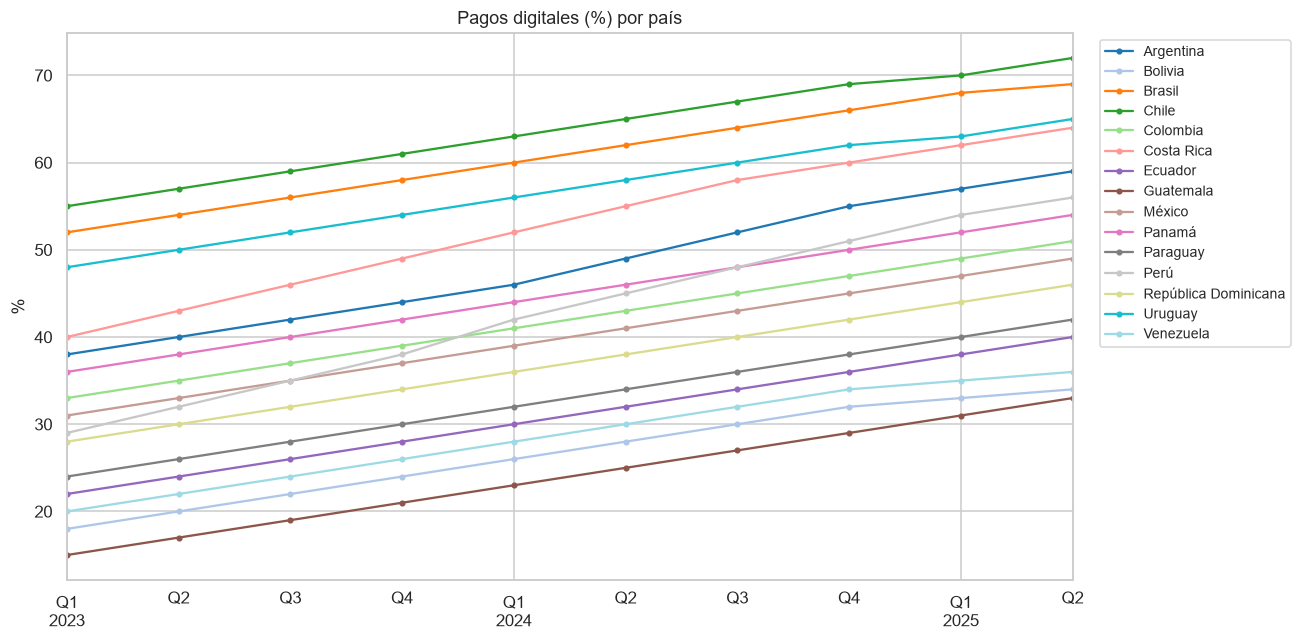

In [31]:
# Pagos digitales: trayectoria por país
piv = df.pivot(index="fecha", columns="pais", values="pagos_digitales_pct")
colores = plt.cm.tab20(np.linspace(0, 1, piv.shape[1]))
ax = piv.plot(figsize=(12, 6), marker="o", ms=3, color=colores)
ax.set_title("Pagos digitales (%) por país"); ax.set_ylabel("%"); ax.set_xlabel("")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", ncol=1, fontsize=9)
plt.tight_layout(); plt.show()

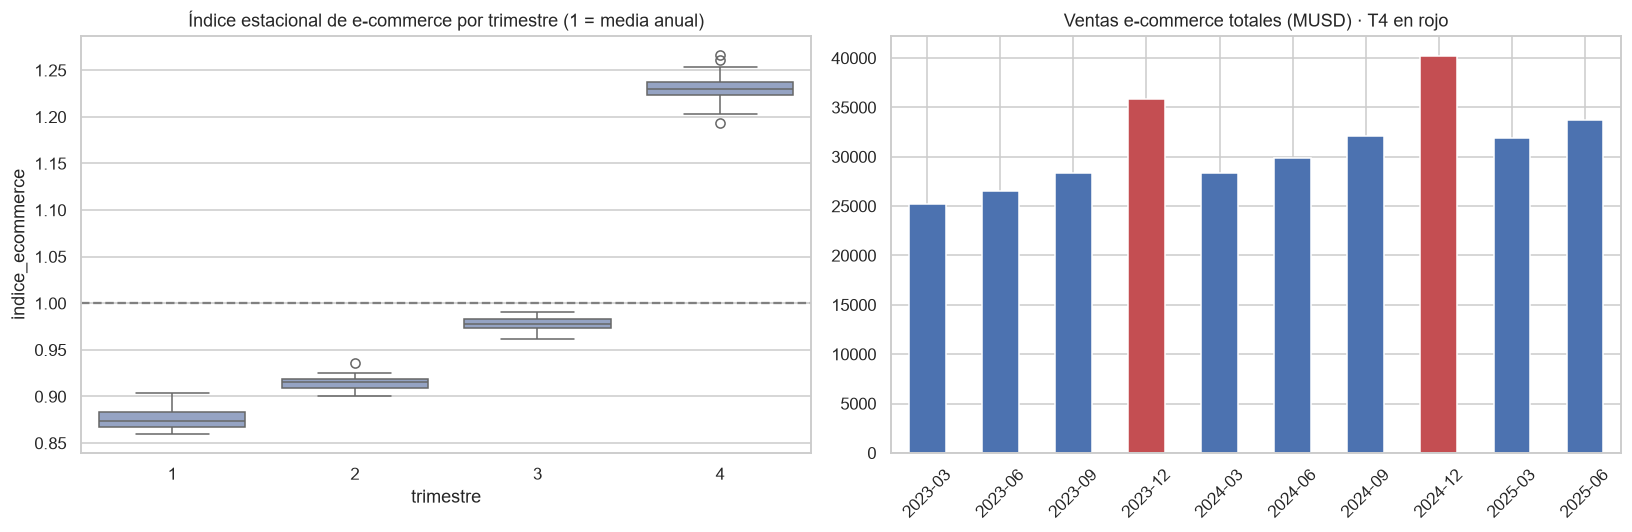

trimestre       1    2    3    4
índice medio 0.88 0.92 0.98 1.23


In [32]:
# Estacionalidad del e-commerce: índice = ventas del trimestre / media anual del país
# (solo 2023 y 2024, años con 4 trimestres completos)
full = df[df["anio"].isin([2023, 2024])].copy()
full["indice_ecommerce"] = full["ventas_ecommerce_musd"] / full.groupby(["pais", "anio"])["ventas_ecommerce_musd"].transform("mean")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=full, x="trimestre", y="indice_ecommerce", color="#8DA0CB", ax=axes[0])
axes[0].axhline(1, color="gray", ls="--"); axes[0].set_title("Índice estacional de e-commerce por trimestre (1 = media anual)")

tot = df.groupby("fecha")["ventas_ecommerce_musd"].sum()
colores_q = ["#C44E52" if d.quarter == 4 else "#4C72B0" for d in tot.index]
tot.index = tot.index.strftime("%Y-%m")
tot.plot.bar(ax=axes[1], color=colores_q)
axes[1].tick_params(axis="x", rotation=45)
axes[1].set_title("Ventas e-commerce totales (MUSD) · T4 en rojo"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

print(full.groupby("trimestre")["indice_ecommerce"].mean().round(3).rename("índice medio").to_frame().T)

## 5. Relaciones entre variables

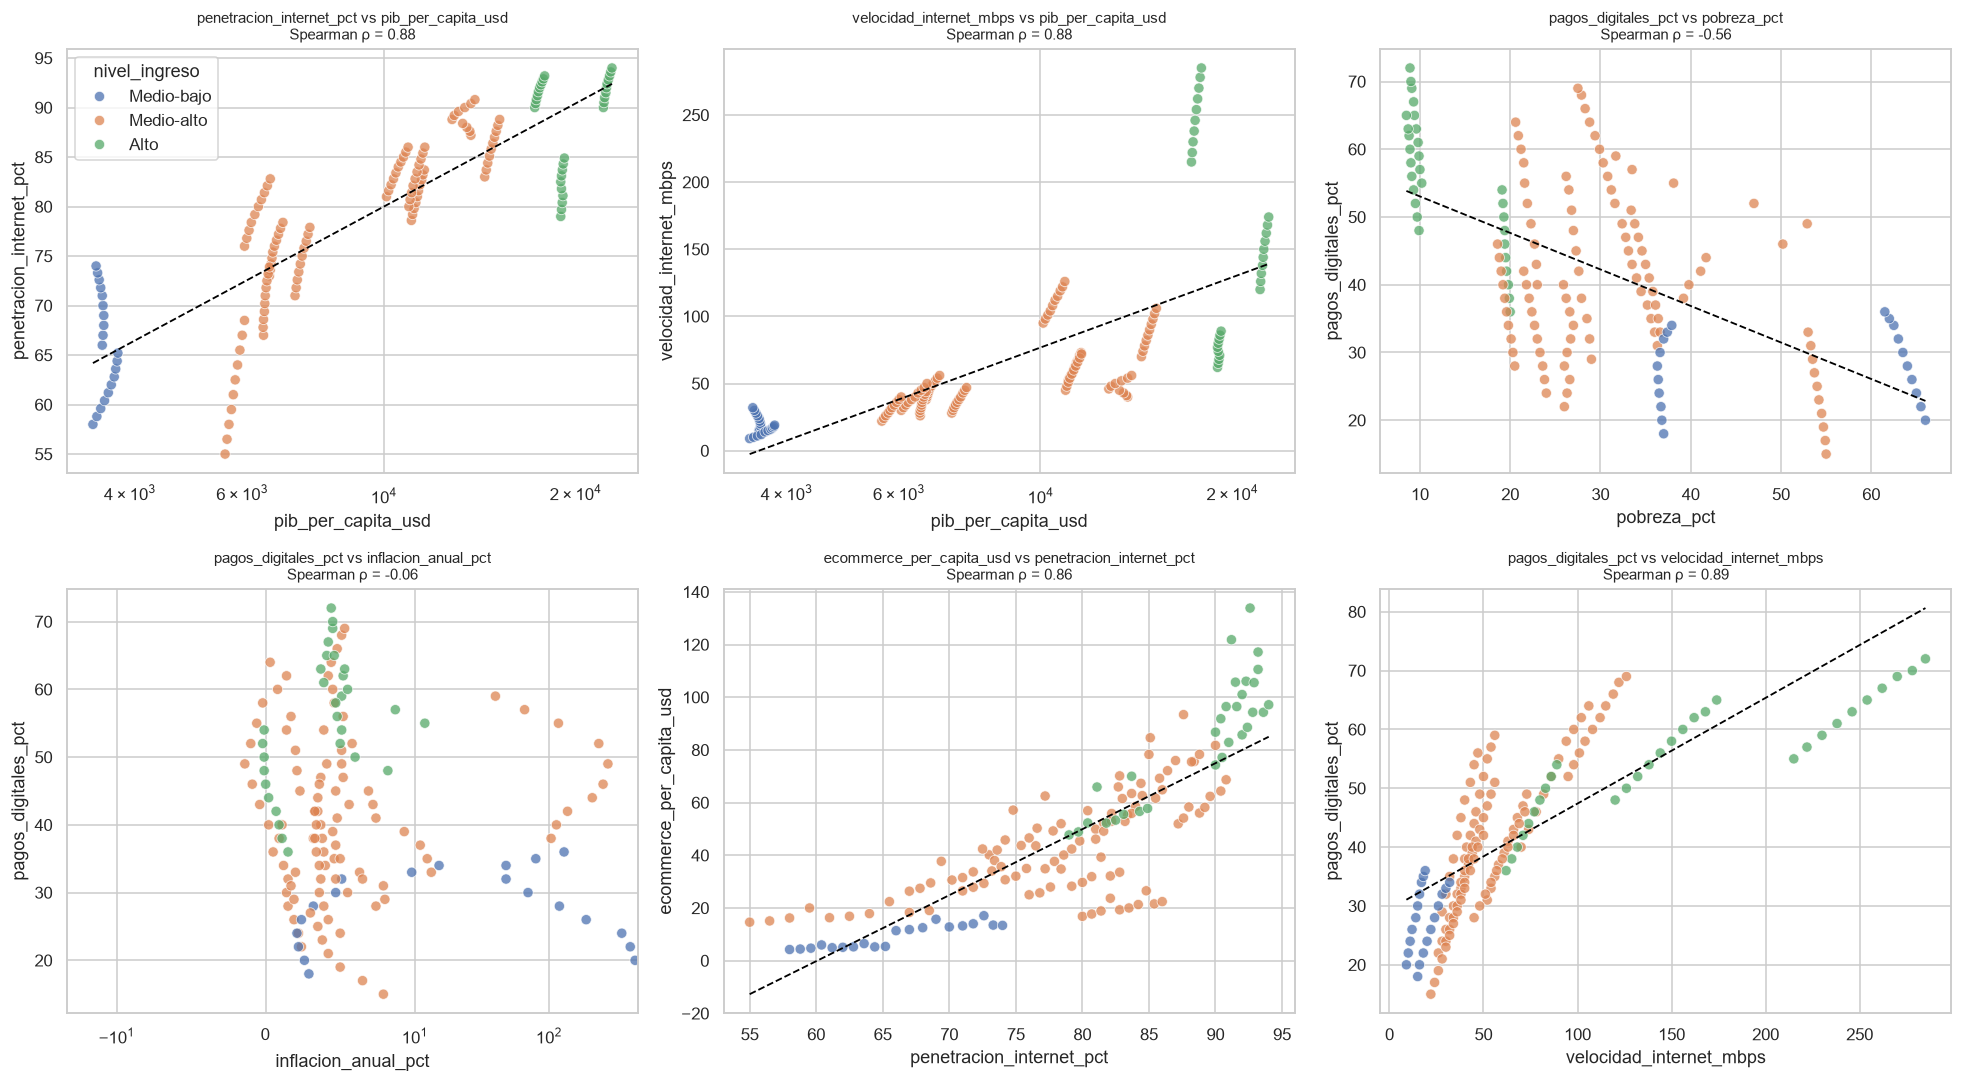

In [33]:
def scatter_reg(ax, x, y, data=df, logx=False, symlog=False, reg=True):
    sns.scatterplot(data=data, x=x, y=y, hue="nivel_ingreso", hue_order=ORDEN_INGRESO, alpha=.75, s=45, ax=ax)
    if logx:
        ax.set_xscale("log")
    if symlog:
        ax.set_xscale("symlog", linthresh=10)
    if reg:
        xs = np.log10(data[x]) if logx else data[x]
        m, b = np.polyfit(xs, data[y], 1)
        g = np.linspace(xs.min(), xs.max(), 100)
        ax.plot(10 ** g if logx else g, m * g + b, color="black", lw=1.2, ls="--")
    rho = data[[x, y]].corr(method="spearman").iloc[0, 1]
    ax.set_title(f"{y} vs {x}\nSpearman ρ = {rho:.2f}", fontsize=10)

pares = [
    ("pib_per_capita_usd", "penetracion_internet_pct", dict(logx=True)),
    ("pib_per_capita_usd", "velocidad_internet_mbps", dict(logx=True)),
    ("pobreza_pct", "pagos_digitales_pct", dict()),
    ("inflacion_anual_pct", "pagos_digitales_pct", dict(symlog=True, reg=False)),
    ("penetracion_internet_pct", "ecommerce_per_capita_usd", dict()),
    ("velocidad_internet_mbps", "pagos_digitales_pct", dict()),
]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for i, (ax, (x, y, kw)) in enumerate(zip(axes.ravel(), pares)):
    scatter_reg(ax, x, y, **kw)
    if i > 0 and ax.get_legend():
        ax.get_legend().remove()
plt.tight_layout(); plt.show()

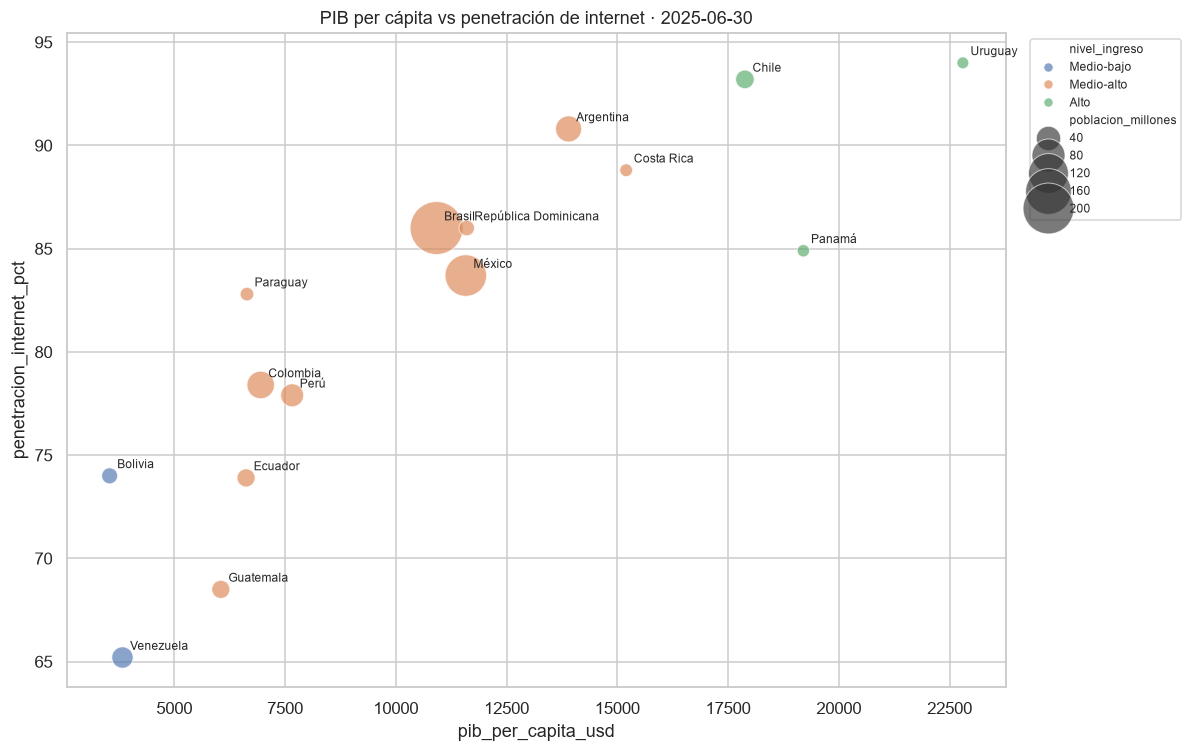

In [34]:
# Gráfico de burbujas: último trimestre (tamaño = población)
fig, ax = plt.subplots(figsize=(11, 7))
sns.scatterplot(data=ult, x="pib_per_capita_usd", y="penetracion_internet_pct", size="poblacion_millones",
                hue="nivel_ingreso", hue_order=ORDEN_INGRESO, sizes=(60, 1200), alpha=.65, ax=ax, legend="brief")
for _, r in ult.iterrows():
    ax.annotate(r["pais"], (r["pib_per_capita_usd"], r["penetracion_internet_pct"]), fontsize=8,
                xytext=(5, 5), textcoords="offset points")
ax.set_title(f"PIB per cápita vs penetración de internet · {ULTIMO.date()}")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

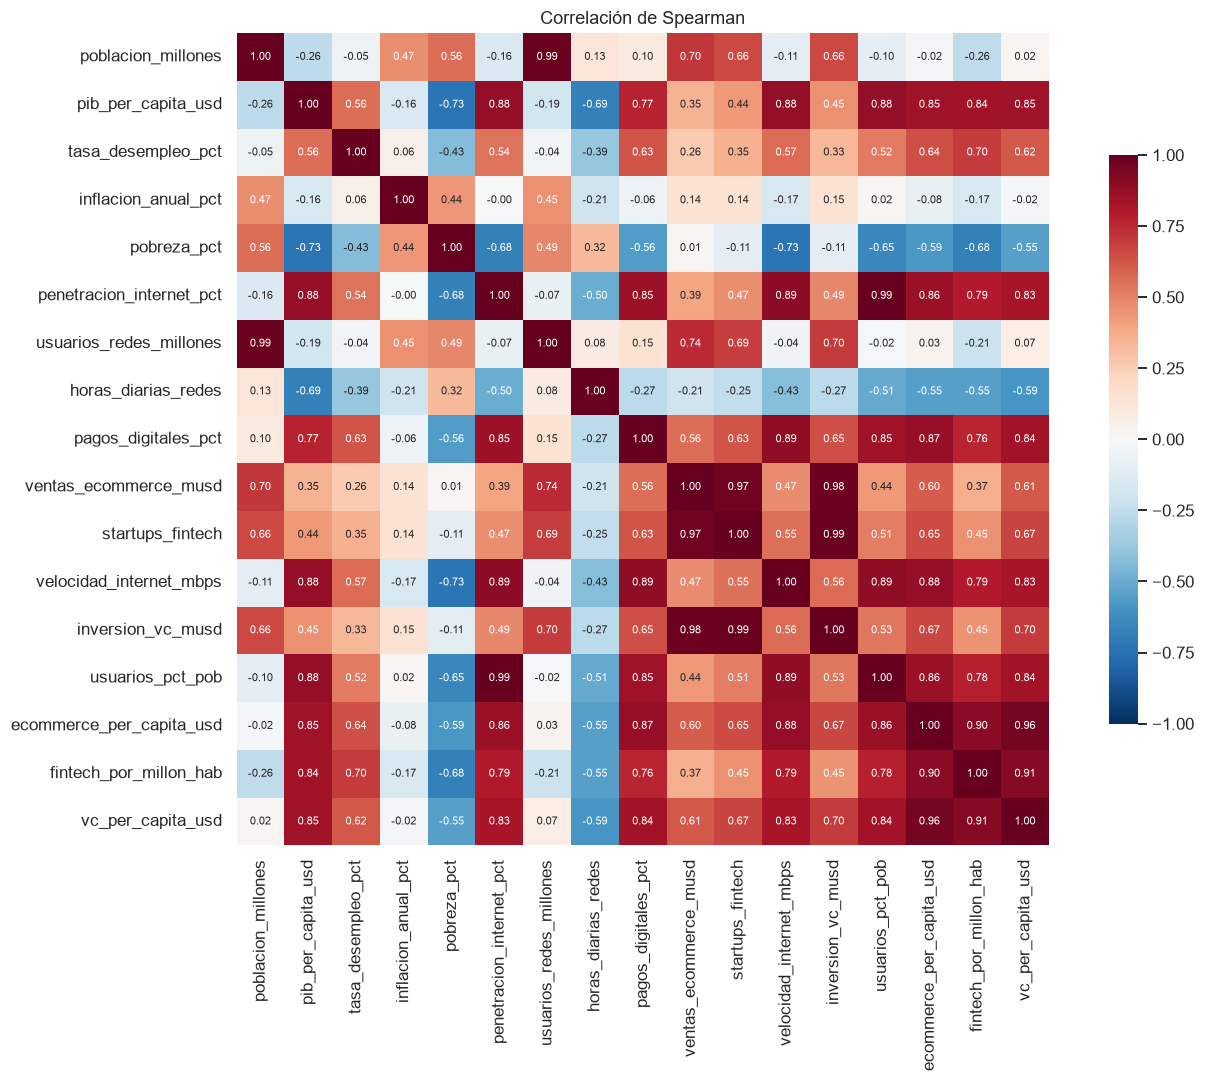

Correlaciones con pagos_digitales_pct:
velocidad_internet_mbps     0.89
ecommerce_per_capita_usd    0.87
penetracion_internet_pct    0.85
usuarios_pct_pob            0.85
vc_per_capita_usd           0.84
pib_per_capita_usd          0.77
fintech_por_millon_hab      0.76
inversion_vc_musd           0.65
startups_fintech            0.63
tasa_desempleo_pct          0.63
ventas_ecommerce_musd       0.56
usuarios_redes_millones     0.15
poblacion_millones          0.10
inflacion_anual_pct        -0.06
horas_diarias_redes        -0.27
pobreza_pct                -0.56


In [35]:
# Matriz de correlación (Spearman: robusta a la asimetría y a los shocks de inflación)
cols_corr = NUM_BASE + DERIVADAS
corr = df[cols_corr].corr(method="spearman")
plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt=".2f", annot_kws={"size": 7}, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": .7})
plt.title("Correlación de Spearman"); plt.tight_layout(); plt.show()

print("Correlaciones con pagos_digitales_pct:")
print(corr["pagos_digitales_pct"].drop("pagos_digitales_pct").sort_values(ascending=False).round(2).to_string())

## 6. Hallazgos clave (calculados a partir de los datos)

In [39]:
def top(col, n=3, asc=False, frame=ult_i):
    s = frame[col].sort_values(ascending=asc).head(n)
    return ", ".join(f"{p} ({v:,.1f})" for p, v in s.items())

rho = lambda a, b: df[[a, b]].corr(method="spearman").iloc[0, 1]
q4 = full.groupby("trimestre")["indice_ecommerce"].mean()
arg = df[df["pais"] == "Argentina"]["inflacion_anual_pct"]
bol = df[df["pais"] == "Bolivia"]["inflacion_anual_pct"]

print("1. DESIGUALDAD DIGITAL")
print("   Mayor penetración de internet :", top("penetracion_internet_pct"))
print("   Menor penetración de internet :", top("penetracion_internet_pct", asc=True))
print("   Mayor % pagos digitales       :", top("pagos_digitales_pct"))
print("   Menor % pagos digitales       :", top("pagos_digitales_pct", asc=True))
print(f"\n2. RELACIONES (Spearman)")
print(f"   PIB pc ↔ penetración internet : {rho('pib_per_capita_usd', 'penetracion_internet_pct'):.2f}")
print(f"   PIB pc ↔ velocidad internet   : {rho('pib_per_capita_usd', 'velocidad_internet_mbps'):.2f}")
print(f"   Pobreza ↔ pagos digitales     : {rho('pobreza_pct', 'pagos_digitales_pct'):.2f}")
print(f"   Inflación ↔ pagos digitales   : {rho('inflacion_anual_pct', 'pagos_digitales_pct'):.2f}")
print(f"\n3. ESTACIONALIDAD: índice e-commerce medio → " + " | ".join(f"T{t}: {v:.2f}" for t, v in q4.items()))
print(f"\n4. SHOCKS MACRO")
print(f"   Argentina: inflación máx {arg.max():.0f}% (en {df.loc[arg.idxmax(), 'periodo']}) → último {arg.iloc[-1]:.0f}%")
print(f"   Bolivia  : inflación {bol.iloc[0]:.1f}% → {bol.iloc[-1]:.1f}%")
dif = df.groupby("pago_instantaneo")["pagos_digitales_pct"].mean()
print(f"\n5. POLÍTICAS: pagos digitales medio con pago instantáneo = {dif.get(True, float('nan')):.1f}% vs sin = {dif.get(False, float('nan')):.1f}%")
print("   (revisa la sección 7: la diferencia depende del nivel de ingreso, no es causal)")
mayor_crec = cambio_pct["ecommerce_per_capita_usd"].sort_values(ascending=False)
print(f"\n6. MAYOR CRECIMIENTO e-commerce per cápita: {mayor_crec.index[0]} ({mayor_crec.iloc[0]:.0f}%), {mayor_crec.index[1]} ({mayor_crec.iloc[1]:.0f}%)")

1. DESIGUALDAD DIGITAL
   Mayor penetración de internet : Uruguay (94.0), Chile (93.2), Argentina (90.8)
   Menor penetración de internet : Venezuela (65.2), Guatemala (68.5), Ecuador (73.9)
   Mayor % pagos digitales       : Chile (72.0), Brasil (69.0), Uruguay (65.0)
   Menor % pagos digitales       : Guatemala (33.0), Bolivia (34.0), Venezuela (36.0)

2. RELACIONES (Spearman)
   PIB pc ↔ penetración internet : 0.88
   PIB pc ↔ velocidad internet   : 0.88
   Pobreza ↔ pagos digitales     : -0.56
   Inflación ↔ pagos digitales   : -0.06

3. ESTACIONALIDAD: índice e-commerce medio → T1: 0.88 | T2: 0.91 | T3: 0.98 | T4: 1.23

4. SHOCKS MACRO
   Argentina: inflación máx 276% (en 2024-T2) → último 40%
   Bolivia  : inflación 2.9% → 15.2%

5. POLÍTICAS: pagos digitales medio con pago instantáneo = 51.0% vs sin = 37.0%
   (revisa la sección 7: la diferencia depende del nivel de ingreso, no es causal)

6. MAYOR CRECIMIENTO e-commerce per cápita: Perú (42%), México (39%)
